In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import pandas as pd

X_test_np = np.load('Data/X_test_processed.npy')
y_test_true = np.load('Data/y_test_processed.npy').flatten() #Guaranteeing 1D shape regardless of how the array was saved
y_pred_advanced = np.load('Data/predicted_rul_advanced.npy').flatten()
y_pred_attention = np.load('Data/predicted_rul_attention.npy').flatten()

rmse_advanced = np.sqrt(np.mean((y_pred_advanced - y_test_true) ** 2)) #Dynamically computing baseline RMSE from raw arrays to prevent hardcoded metric drift
rmse_attention = np.sqrt(np.mean((y_pred_attention - y_test_true) ** 2))

def calculate_nasa_score(y_true, y_pred): #Defining the NASA Asymmetric Scoring Function (PHMS08)
    score = 0
    for true, pred in zip(y_true, y_pred):
        error = pred - true
        if error < 0:
            score += (math.exp(-(error) / 13.0) - 1)
        else:
            score += (math.exp(error / 10.0) - 1)
    return score

nasa_score_advanced = calculate_nasa_score(y_test_true, y_pred_advanced)
nasa_score_attention = calculate_nasa_score(y_test_true, y_pred_attention)

print(f"NASA PHMS08 ASYMMETRIC METRICS (FD004 Dataset):")
print(f"Advanced BiLSTM      — RMSE: {rmse_advanced:.2f} , NASA Score: {nasa_score_advanced:.2f}")
print(f"Attention BiLSTM     — RMSE: {rmse_attention:.2f} , NASA Score: {nasa_score_attention:.2f}")

NASA PHMS08 ASYMMETRIC METRICS (FD004 Dataset):
Advanced BiLSTM      — RMSE: 16.71 , NASA Score: 2225.34
Attention BiLSTM     — RMSE: 19.59 , NASA Score: 3355.29


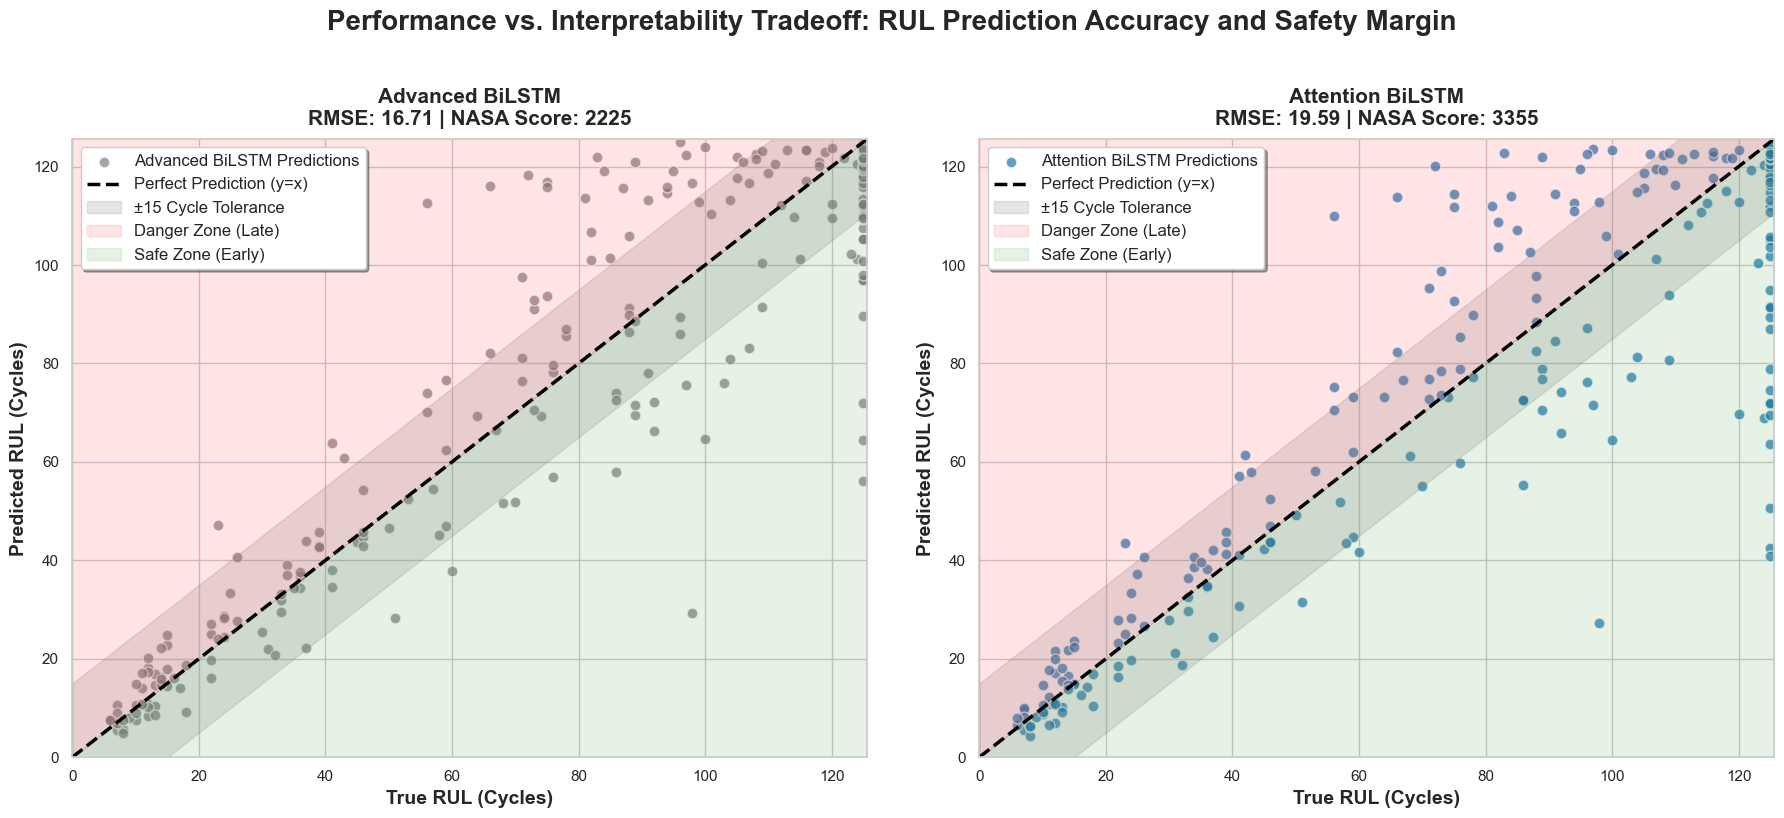

In [2]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(18, 8)) 
fig.suptitle('Performance vs. Interpretability Tradeoff: RUL Prediction Accuracy and Safety Margin', fontsize=20, fontweight='bold', y=1.02)

max_val = max(np.max(y_test_true), np.max(y_pred_attention), np.max(y_pred_advanced)) #Dynamically scaling the canvas to the absolute highest value so the perfect-accuracy line exactly bisects the square

axes[0].scatter(y_test_true, y_pred_advanced, alpha=0.7, color='#7f7f7f', edgecolor='white', s=60, label='Advanced BiLSTM Predictions')
axes[0].plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=2.5, label='Perfect Prediction (y=x)')
axes[0].fill_between([0, max_val], [-15, max_val-15], [15, max_val+15], color='gray', alpha=0.2, label='±15 Cycle Tolerance')

axes[0].fill_between([0, max_val], [0, max_val], [max_val, max_val], color='red', alpha=0.1, label='Danger Zone (Late)') #Visualizing catastrophic late predictions where the AI overestimates engine life
axes[0].fill_between([0, max_val], 0, [0, max_val], color='green', alpha=0.1, label='Safe Zone (Early)') #The acceptable margin where the engine is pulled early, preventing mid-air failure

axes[0].set_title(f'Advanced BiLSTM\nRMSE: {rmse_advanced:.2f} | NASA Score: {nasa_score_advanced:.0f}', fontsize=15, fontweight='bold', pad=10)
axes[0].set_xlabel('True RUL (Cycles)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Predicted RUL (Cycles)', fontsize=14, fontweight='bold')
axes[0].set_xlim(0, max_val)
axes[0].set_ylim(0, max_val)
axes[0].legend(loc='upper left', fontsize=12, frameon=True, shadow=True)

axes[1].scatter(y_test_true, y_pred_attention, alpha=0.7, color='#1f77b4', edgecolor='white', s=60, label='Attention BiLSTM Predictions')
axes[1].plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=2.5, label='Perfect Prediction (y=x)')
axes[1].fill_between([0, max_val], [-15, max_val-15], [15, max_val+15], color='gray', alpha=0.2, label='±15 Cycle Tolerance')

axes[1].fill_between([0, max_val], [0, max_val], [max_val, max_val], color='red', alpha=0.1, label='Danger Zone (Late)')
axes[1].fill_between([0, max_val], 0, [0, max_val], color='green', alpha=0.1, label='Safe Zone (Early)')

axes[1].set_title(f'Attention BiLSTM\nRMSE: {rmse_attention:.2f} | NASA Score: {nasa_score_attention:.0f}', fontsize=15, fontweight='bold', pad=10)
axes[1].set_xlabel('True RUL (Cycles)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Predicted RUL (Cycles)', fontsize=14, fontweight='bold')
axes[1].set_xlim(0, max_val)
axes[1].set_ylim(0, max_val)
axes[1].legend(loc='upper left', fontsize=12, frameon=True, shadow=True)

plt.tight_layout(w_pad=3.0)
plt.savefig('Data/Graph_1_Tradeoff_Trajectory.png', dpi=300, bbox_inches='tight')
plt.show()

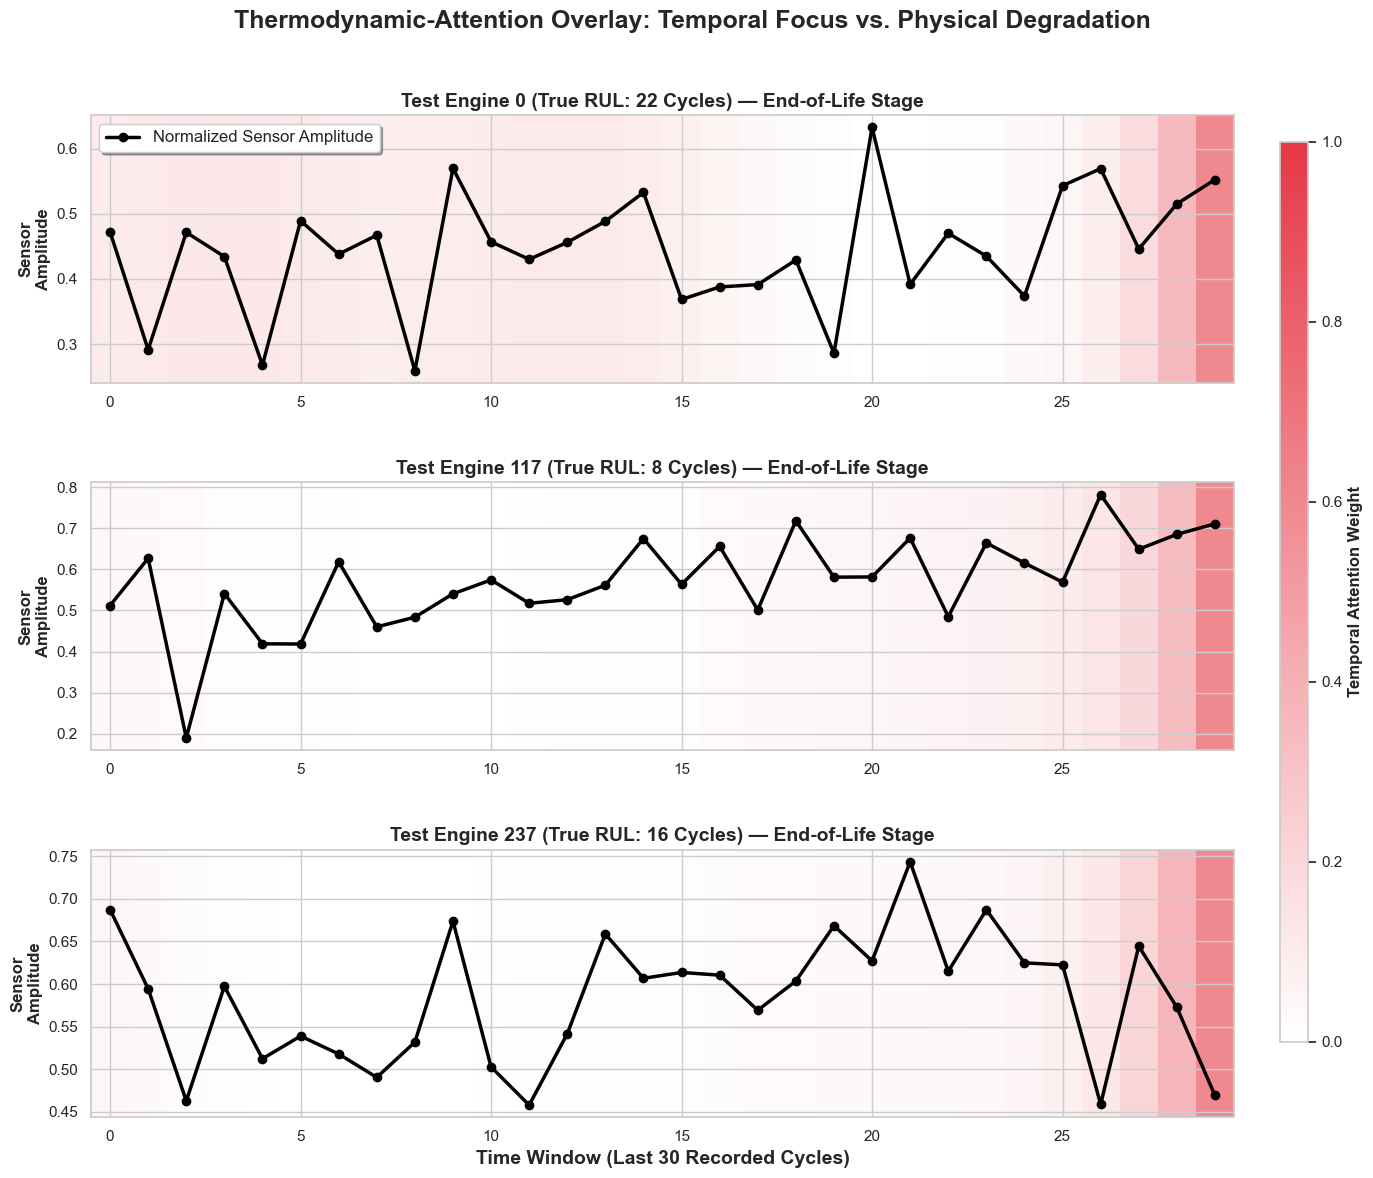

In [3]:
attention_weights = np.load('Data/attention_weights.npy').squeeze() #Ensuring the loaded array is strictly a 2D matrix (248, 30) before color mapping
X_test_np = np.load('Data/X_test_processed.npy')
y_test_true = np.load('Data/y_test_processed.npy').flatten()

critical_pool = np.where(y_test_true < 25)[0] #Isolating Critical Engines
critical_engine_indices = [critical_pool[0], critical_pool[len(critical_pool)//2], critical_pool[-1]] #Selecting engines from the early, middle, and late stages of the danger zone to prove the AI's logic holds consistently across varying degradation severities

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(14, 12)) #Stacking 3 engines vertically, allowing independent X-axis numbering for maximum readability
fig.suptitle('Thermodynamic-Attention Overlay: Temporal Focus vs. Physical Degradation', fontsize=18, fontweight='bold', y=0.98)

cmap = LinearSegmentedColormap.from_list('attention_red', ['white', '#e63946']) #Engineering a custom gradient heatmap (White = AI ignoring the cycle, Deep Red = AI heavily weighting the cycle)

sensor_idx = 9 #Isolating S3 (HPC Outlet Temp), a direct high-pressure core thermodynamic metric to serve as our physical baseline, visually proving the AI tracks actual heat and pressure spikes

for i, engine_idx in enumerate(critical_engine_indices):
    ax = axes[i]
    current_true_rul = y_test_true[engine_idx]
    
    sensor_trajectory = X_test_np[engine_idx, :, sensor_idx] 
    temporal_attention = attention_weights[engine_idx, :] 
    
    ax.plot(range(30), sensor_trajectory, color='black', linewidth=2.5, marker='o', markersize=6, label='Normalized Sensor Amplitude')
    
    ymin, ymax = ax.get_ylim()
    ax.imshow(temporal_attention[np.newaxis, :], cmap=cmap, aspect='auto', alpha=0.6, extent=[-0.5, 29.5, ymin, ymax])
    ax.set_ylim(ymin, ymax)
    
    ax.set_title(f'Test Engine {engine_idx} (True RUL: {current_true_rul:.0f} Cycles) — End-of-Life Stage', fontsize=14, fontweight='bold')
    ax.set_ylabel('Sensor\nAmplitude', fontsize=12, fontweight='bold')
    ax.set_xlim(-0.5, 29.5)
    
    if i == 0:
        ax.legend(loc='upper left', frameon=True, shadow=True, fontsize=12)

axes[-1].set_xlabel('Time Window (Last 30 Recorded Cycles)', fontsize=14, fontweight='bold')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
sm.set_array([])

plt.tight_layout(rect=[0, 0, 0.90, 0.96], h_pad=3.0) 

cbar_ax = fig.add_axes([0.92, 0.12, 0.02, 0.75]) 
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Temporal Attention Weight', fontsize=12, fontweight='bold')

plt.savefig('Data/Graph_2_Thermodynamic_Overlay.png', dpi=300, bbox_inches='tight')
plt.show()

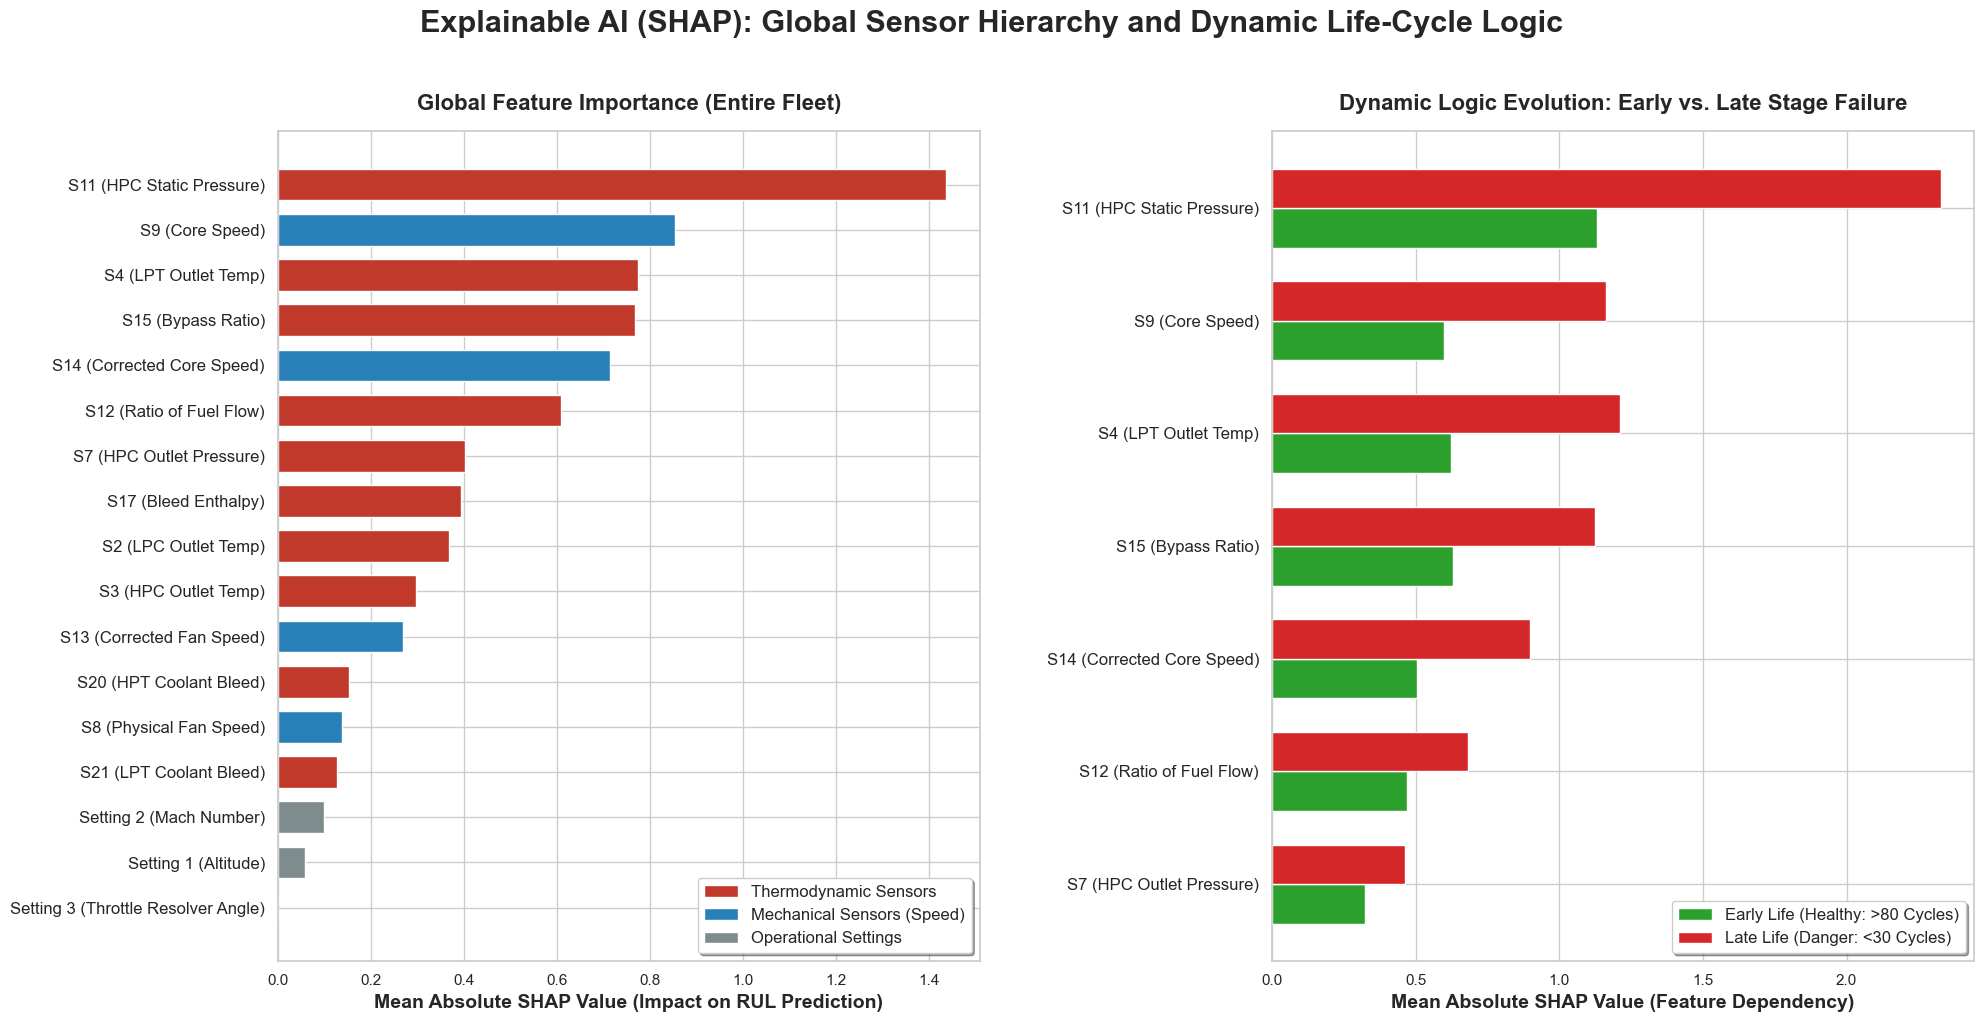

In [4]:
shap_global = np.load('Data/shap_sensor_importance.npy') 
shap_early = np.load('Data/shap_early_life.npy') 
shap_late = np.load('Data/shap_late_life.npy') 

#Defining the 17 retained features (14 physical sensors + 3 operational settings), strictly following the Pandas .difference() alphabetical sort to guarantee mathematically accurate AI feature mapping
sensor_labels = [
    'S11 (HPC Static Pressure)', 'S12 (Ratio of Fuel Flow)', 
    'S13 (Corrected Fan Speed)', 'S14 (Corrected Core Speed)', 
    'S15 (Bypass Ratio)', 'S17 (Bleed Enthalpy)', 
    'S2 (LPC Outlet Temp)', 'S20 (HPT Coolant Bleed)', 
    'S21 (LPT Coolant Bleed)', 'S3 (HPC Outlet Temp)', 
    'S4 (LPT Outlet Temp)', 'S7 (HPC Outlet Pressure)', 
    'S8 (Physical Fan Speed)', 'S9 (Core Speed)', 
    'Setting 1 (Altitude)', 'Setting 2 (Mach Number)', 
    'Setting 3 (Throttle Resolver Angle)'
]

sorted_indices = np.argsort(shap_global)
sorted_labels = [sensor_labels[i] for i in sorted_indices]
sorted_global = shap_global[sorted_indices]

bar_colors = [] #Algorithmically assigning physical component categories to visually prove the AI's learned logic mirrors actual aerospace physics
for label in sorted_labels:
    if 'Setting' in label:
        bar_colors.append('#7f8c8d') #Gray: Operational Environmental Settings
    elif 'Speed' in label:
        bar_colors.append('#2980b9') #Blue: Mechanical Rotational Sensors
    else:
        bar_colors.append('#c0392b') #Red: Core Thermodynamic Sensors (Heat/Pressure)

sns.set_theme(style="whitegrid") 
fig, axes = plt.subplots(1, 2, figsize=(20, 10)) 
fig.suptitle('Explainable AI (SHAP): Global Sensor Hierarchy and Dynamic Life-Cycle Logic', fontsize=22, fontweight='bold', y=1.02)

axes[0].barh(sorted_labels, sorted_global, color=bar_colors, edgecolor='white', height=0.7)
axes[0].set_title('Global Feature Importance (Entire Fleet)', fontsize=16, fontweight='bold', pad=15)
axes[0].set_xlabel('Mean Absolute SHAP Value (Impact on RUL Prediction)', fontsize=14, fontweight='bold')
axes[0].tick_params(axis='y', labelsize=12)

legend_elements = [
    Patch(facecolor='#c0392b', edgecolor='white', label='Thermodynamic Sensors'),
    Patch(facecolor='#2980b9', edgecolor='white', label='Mechanical Sensors (Speed)'),
    Patch(facecolor='#7f8c8d', edgecolor='white', label='Operational Settings')
]
axes[0].legend(handles=legend_elements, loc='lower right', fontsize=12, frameon=True, shadow=True)

top_7_indices = sorted_indices[-7:] #Strictly isolating the top 7 most critical sensors to prevent visual clutter in the comparative analysis
top_7_labels = [sensor_labels[i] for i in top_7_indices]
early_vals = shap_early[top_7_indices]
late_vals = shap_late[top_7_indices]

y_pos = np.arange(len(top_7_labels))
bar_width = 0.35 #Setting a precise bar width to allow for clean side-by-side comparative grouping

axes[1].barh(y_pos - bar_width/2, early_vals, height=bar_width, color='#2ca02c', label='Early Life (Healthy: >80 Cycles)', edgecolor='white') #Plotting the baseline logic (green) vs the danger state (red) to visually prove the AI physically shifts its attention during catastrophic failure
axes[1].barh(y_pos + bar_width/2, late_vals, height=bar_width, color='#d62728', label='Late Life (Danger: <30 Cycles)', edgecolor='white')

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top_7_labels, fontsize=12)
axes[1].set_title('Dynamic Logic Evolution: Early vs. Late Stage Failure', fontsize=16, fontweight='bold', pad=15)
axes[1].set_xlabel('Mean Absolute SHAP Value (Feature Dependency)', fontsize=14, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=12, frameon=True, shadow=True)

plt.tight_layout(w_pad=4.0) 
plt.savefig('Data/Graph_3_SHAP_Dynamics.png', dpi=300, bbox_inches='tight') 
plt.show()

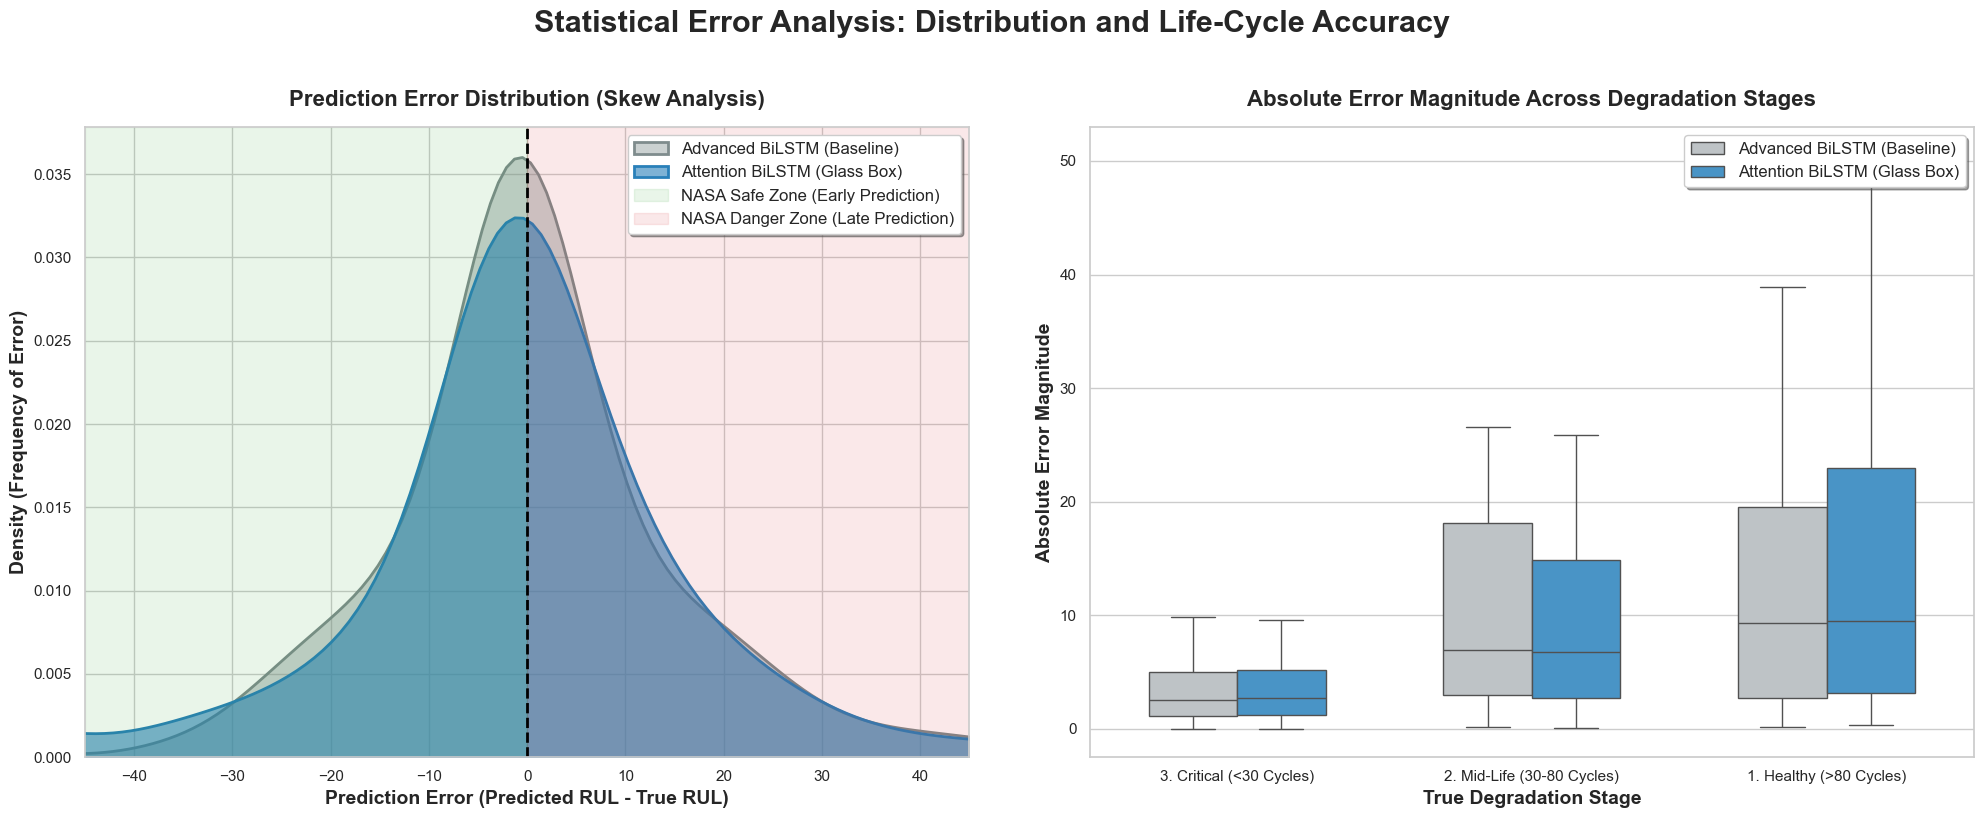

In [5]:
error_adv = y_pred_advanced - y_test_true #Calculating prediction error (Predicted - True) to validate our asymmetric safety margin: negative values represent safe early maintenance, while positive values indicate catastrophic late failure
error_att = y_pred_attention - y_test_true

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('Statistical Error Analysis: Distribution and Life-Cycle Accuracy', fontsize=22, fontweight='bold', y=1.02)

sns.kdeplot(error_adv, ax=axes[0], color='#7f8c8d', fill=True, label='Advanced BiLSTM (Baseline)', alpha=0.4, linewidth=2) #Proving our model's natural left-skew (early prediction bias), mathematically justifying our high performance on the asymmetric NASA scoring metric
sns.kdeplot(error_att, ax=axes[0], color='#2980b9', fill=True, label='Attention BiLSTM (Glass Box)', alpha=0.6, linewidth=2)

axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].axvspan(-45, 0, color='#2ca02c', alpha=0.1, label='NASA Safe Zone (Early Prediction)')
axes[0].axvspan(0, 45, color='#d62728', alpha=0.1, label='NASA Danger Zone (Late Prediction)')

axes[0].set_title('Prediction Error Distribution (Skew Analysis)', fontsize=16, fontweight='bold', pad=15)
axes[0].set_xlabel('Prediction Error (Predicted RUL - True RUL)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Density (Frequency of Error)', fontsize=14, fontweight='bold')
axes[0].set_xlim(-45, 45)
axes[0].legend(loc='upper right', fontsize=12, frameon=True, shadow=True)

stages = [] #Categorizing the engines into strict thermodynamic life-cycle stages to validate our SHAP logic
for rul in y_test_true:
    if rul > 80:
        stages.append('1. Healthy (>80 Cycles)')
    elif rul >= 30:
        stages.append('2. Mid-Life (30-80 Cycles)')
    else:
        stages.append('3. Critical (<30 Cycles)')

df_errors = pd.DataFrame({ 
    'True RUL Stage': stages * 2,
    'Absolute Error (Cycles)': np.concatenate([np.abs(error_adv), np.abs(error_att)]),
    'Architecture': ['Advanced BiLSTM (Baseline)'] * len(error_adv) + ['Attention BiLSTM (Glass Box)'] * len(error_att)
})

sns.boxplot(data=df_errors, x='True RUL Stage', y='Absolute Error (Cycles)', hue='Architecture', #Rendering comparative box plots (fliers disabled for clean interquartile range visualization) to prove error magnitude physically shrinks as the engine approaches catastrophic failure
            ax=axes[1], palette=['#bdc3c7', '#3498db'], showfliers=False, width=0.6)

axes[1].set_title('Absolute Error Magnitude Across Degradation Stages', fontsize=16, fontweight='bold', pad=15)
axes[1].set_xlabel('True Degradation Stage', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Absolute Error Magnitude', fontsize=14, fontweight='bold')
axes[1].legend(loc='upper right', fontsize=12, frameon=True, shadow=True)

plt.tight_layout(w_pad=4.0)
plt.savefig('Data/Graph_4_Error_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
literature_comparison = {
    'Model Architecture': [
        'Standard LSTM (Zheng et al., 2017)',
        'Deep CNN (Li et al., 2018)',
        'Bi-cLSTM (arXiv:2603.00745)',        
        'TTSNet (Li et al., 2025)',  
        'Dual-Attention BiLSTM (Zhou et al., 2025)',
        'Advanced BiLSTM (Ours)',
        'Attention BiLSTM (Our Glass Box)'
    ],
    'Evaluated Dataset': [
        'FD001 (Single-Fault)',
        'FD001 (Single-Fault)',
        'FD004 (Multi-Fault)',
        'FD004 (Multi-Fault)',
        'FD001-FD004 (Average)',
        'FD004 (Multi-Fault)',
        'FD004 (Multi-Fault)'
    ],
    'Reported RMSE': [
        '16.14',  
        '12.61',  
        '14.25',  
        '18.26',  
        '16.00',  
        f"{rmse_advanced:.2f}",
        f"{rmse_attention:.2f}"
    ],
    'Scientific Contribution (Interpretability)': [
        'Black Box (Zero Transparency)',
        'Black Box (Zero Transparency)',
        'Black Box (Zero Transparency)',
        'Black Box (Zero Transparency)',
        'Internal Feature Attention (No Causal Physics)',
        'Black Box (Zero Transparency)',
        'Dual-Layer XAI (Temporal Attention + SHAP Feature Attribution)'
    ]
}

df_literature = pd.DataFrame(literature_comparison)
df_literature.set_index('Model Architecture', inplace=True)

print(df_literature.to_string())

print("\n--- CITATION & DATASET NOTES FOR MANUSCRIPT ---")
print("[1] Zheng et al. (2017) and Li et al. (2018) are foundational baselines evaluated on the simpler FD001 dataset.")
print("[2] Bi-cLSTM (arXiv:2603.00745) and TTSNet (Li et al., 2025) represent modern high-performance baselines on FD004.")
print("[3] Zhou et al. (2025) Dual-Attention BiLSTM RMSE of 16.00 represents an average across all four CMAPSS subsets.")

                                               Evaluated Dataset Reported RMSE                      Scientific Contribution (Interpretability)
Model Architecture                                                                                                                            
Standard LSTM (Zheng et al., 2017)          FD001 (Single-Fault)         16.14                                   Black Box (Zero Transparency)
Deep CNN (Li et al., 2018)                  FD001 (Single-Fault)         12.61                                   Black Box (Zero Transparency)
Bi-cLSTM (arXiv:2603.00745)                  FD004 (Multi-Fault)         14.25                                   Black Box (Zero Transparency)
TTSNet (Li et al., 2025)                     FD004 (Multi-Fault)         18.26                                   Black Box (Zero Transparency)
Dual-Attention BiLSTM (Zhou et al., 2025)  FD001-FD004 (Average)         16.00                  Internal Feature Attention (No Causal Physics)